In [1]:
!pip -q install requests beautifulsoup4 pandas numpy scikit-learn pillow tqdm matplotlib seaborn

In [2]:
import os, re, time, json, math, warnings
from pathlib import Path
from urllib.parse import urljoin, urlparse
import requests
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup
from PIL import Image
from io import BytesIO
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.cluster import MiniBatchKMeans, DBSCAN
from sklearn.decomposition import TruncatedSVD, PCA

warnings.filterwarnings("ignore")
BASE_URL = "https://dumecom.vercel.app/"
PRODUCT_URL_PREFIX = urljoin(BASE_URL, "products/")
DATA_DIR = Path("product_matching_data")
DATA_DIR.mkdir(exist_ok=True)
IMAGE_DIR = DATA_DIR / "images"
IMAGE_DIR.mkdir(exist_ok=True)
HEADERS = {"User-Agent": "Mozilla/5.0 (compatible; ProductMatchingStudentProject/1.0)"}
session = requests.Session()
session.headers.update(HEADERS)
print("Ready. Data directory:", DATA_DIR.resolve())

Ready. Data directory: /content/product_matching_data


In [5]:
def get_soup(url, timeout=25):
    response = session.get(url, timeout=timeout)
    response.raise_for_status()
    return BeautifulSoup(response.text, "html.parser")

def get_product_links(soup, page_url):
    found = {}
    for a in soup.find_all("a", href=True):
        href = urljoin(page_url, a["href"])
        match = re.search(r"/products/(M\d+)\.html", urlparse(href).path, re.I)
        if match:
            found[match.group(1).upper()] = href
    return found

def get_next_page(soup, page_url):

    a = soup.find("a", rel=lambda x: x and "next" in x)
    if a and a.get("href"):
        return urljoin(page_url, a["href"])
    for a in soup.find_all("a", href=True):
        if "next" in a.get_text(" ", strip=True).lower():
            return urljoin(page_url, a["href"])
    return None

catalog = {}
page_url = BASE_URL
visited_pages = set()
MAX_PAGES = 150

for page_no in range(1, MAX_PAGES + 1):
    if page_url in visited_pages:
        break
    visited_pages.add(page_url)
    soup = get_soup(page_url)
    page_products = get_product_links(soup, page_url)
    catalog.update(page_products)
    print(f"Page {page_no}: {len(page_products)} product links; total unique: {len(catalog)}")
    next_url = get_next_page(soup, page_url)
    if not next_url or next_url == page_url:
        break
    page_url = next_url
    time.sleep(0.25)

print("Total product references discovered:", len(catalog))
if not catalog:
    raise RuntimeError("No product links found. Inspect the website HTML and update get_product_links().")

Page 1: 48 product links; total unique: 48
Page 2: 48 product links; total unique: 96
Page 3: 48 product links; total unique: 144
Page 4: 48 product links; total unique: 192
Page 5: 48 product links; total unique: 240
Page 6: 48 product links; total unique: 288
Page 7: 48 product links; total unique: 336
Page 8: 48 product links; total unique: 384
Page 9: 48 product links; total unique: 432
Page 10: 48 product links; total unique: 480
Page 11: 48 product links; total unique: 528
Page 12: 48 product links; total unique: 576
Page 13: 48 product links; total unique: 624
Page 14: 48 product links; total unique: 672
Page 15: 48 product links; total unique: 720
Page 16: 48 product links; total unique: 768
Page 17: 48 product links; total unique: 816
Page 18: 48 product links; total unique: 864
Page 19: 48 product links; total unique: 912
Page 20: 48 product links; total unique: 960
Page 21: 48 product links; total unique: 1008
Page 22: 48 product links; total unique: 1056
Page 23: 48 product

In [7]:
def parse_price(text):
    if not text:
        return np.nan
    nums = re.findall(r"\d[\d.,]*", text.replace(" ", ""))
    if not nums:
        return np.nan
    raw = nums[0].replace(",", "").replace(".", "")
    try:
        return float(raw)
    except Exception:
        return np.nan

def extract_product(ref, detail_url):
    row = {"product_ref": ref, "detail_url": detail_url, "title": "", "price": np.nan,
           "image_url": "", "image_path": ""}
    try:
        soup = get_soup(detail_url)
        h1 = soup.find("h1")
        row["title"] = h1.get_text(" ", strip=True) if h1 else soup.title.get_text(" ", strip=True) if soup.title else ""
        page_text = soup.get_text(" ", strip=True)
        ref_match = re.search(r"Reference:\s*(M\d+)", page_text, re.I)
        if ref_match:
            row["product_ref"] = ref_match.group(1).upper()

        imgs = soup.find_all("img")
        chosen = None
        title_low = row["title"].lower()
        for img in imgs:
            alt = (img.get("alt") or "").lower()
            src = img.get("src") or img.get("data-src") or ""
            if src and (title_low[:18] in alt or "product" in alt):
                chosen = img
                break
        if chosen is None:
            for img in imgs:
                if img.get("src") or img.get("data-src"):
                    chosen = img
                    break
        if chosen:
            src = chosen.get("src") or chosen.get("data-src")
            row["image_url"] = urljoin(detail_url, src)
            ext = Path(urlparse(row["image_url"]).path).suffix.lower()
            if ext not in [".jpg", ".jpeg", ".png", ".webp"]:
                ext = ".jpg"
            image_path = IMAGE_DIR / f"{row['product_ref']}{ext}"
            row["image_path"] = str(image_path)
            if not image_path.exists():
                try:
                    r = session.get(row["image_url"], timeout=25)
                    r.raise_for_status()
                    Image.open(BytesIO(r.content)).convert("RGB").save(image_path, quality=90)
                except Exception:
                    row["image_path"] = ""

        price_match = re.search(r"(?:₹|Rs\.?|Rp\.?|\$)\s*([\d,]+(?:\.\d+)?)", page_text, re.I)
        if price_match:
            row["price"] = parse_price(price_match.group(1))
    except Exception as e:
        row["scrape_error"] = str(e)[:250]
    return row

records = []
for ref, url in tqdm(catalog.items(), desc="Scraping product pages"):
    records.append(extract_product(ref, url))
    time.sleep(0.15)

products = pd.DataFrame(records).drop_duplicates("product_ref").reset_index(drop=True)
products["title"] = products["title"].fillna("").astype(str)
products.to_csv(DATA_DIR / "products.csv", index=False)
print("Products saved:", len(products))
display(products.head())
print("Titles missing:", (products.title.str.strip() == "").sum())
print("Images downloaded:", products.image_path.fillna("").astype(bool).sum())

Scraping product pages:   0%|          | 0/3400 [00:00<?, ?it/s]

Products saved: 3400


,product_ref,detail_url,title,price,image_url,image_path
0,M000001,https://dumecom.vercel.app/products/M000001.html,KAOS KAKI PENDEK MINI SOCKS WARNA WARNI,1599.0,https://dumecom.vercel.app/images/M000001.jpg,product_matching_data/images/M000001.jpg
1,M000002,https://dumecom.vercel.app/products/M000002.html,MUKENA ANAK FROZEN TAS SAJADAH,2999.0,https://dumecom.vercel.app/images/M000002.jpg,product_matching_data/images/M000002.jpg
2,M000003,https://dumecom.vercel.app/products/M000003.html,Official Distributor Focallure Full Coverage L...,649.0,https://dumecom.vercel.app/images/M000003.jpg,product_matching_data/images/M000003.jpg
3,M000004,https://dumecom.vercel.app/products/M000004.html,Nestle Cerelac Bubur Sereal Bayi Risenutri,2499.0,https://dumecom.vercel.app/images/M000004.jpg,product_matching_data/images/M000004.jpg
4,M000005,https://dumecom.vercel.app/products/M000005.html,Sweety bronze pants M58,2499.0,https://dumecom.vercel.app/images/M000005.jpg,product_matching_data/images/M000005.jpg


Titles missing: 0
Images downloaded: 3400


In [9]:
def find_evaluation_file():
    candidates = [Path("/kaggle/input")]
    for root in candidates:
        if root.exists():
            matches = list(root.rglob("evaluation_pairs.csv"))
            if matches:
                return matches[0]
    local = Path("evaluation_pairs.csv")
    if local.exists():
        return local
    return None

eval_path = find_evaluation_file()
if eval_path is None:
    try:
        from google.colab import files
        print("Upload evaluation_pairs.csv")
        uploaded = files.upload()
        eval_path = Path("evaluation_pairs.csv")
    except Exception:
        raise FileNotFoundError("Place evaluation_pairs.csv in the notebook folder or attach the Kaggle competition data.")

pairs = pd.read_csv(eval_path)
print("Evaluation file:", eval_path)
print("Shape:", pairs.shape)
display(pairs.head())

PAIR_COLS = None
if PAIR_COLS is None:
    ref_pattern = re.compile(r"^M\d+$", re.I)
    scores = {}
    for col in pairs.columns:
        vals = pairs[col].dropna().astype(str).head(1000)
        scores[col] = sum(bool(ref_pattern.match(v.strip())) for v in vals)
    ranked = sorted(scores, key=scores.get, reverse=True)
    if len(ranked) < 2 or scores[ranked[1]] == 0:
        raise ValueError("Could not detect the two product-reference columns. Set PAIR_COLS manually.")
    PAIR_COLS = ranked[:2]
print("Pair columns:", PAIR_COLS)

Evaluation file: evaluation_pairs.csv
Shape: (6000, 3)


,pair_ref,item_a,item_b
0,Q000001,M001717,M002153
1,Q000002,M002364,M003380
2,Q000003,M000218,M001820
3,Q000004,M001448,M001956
4,Q000005,M000041,M001166


Pair columns: ['item_a', 'item_b']


In [10]:
def clean_title(value):
    value = str(value).lower()
    value = re.sub(r"[^a-z0-9]+", " ", value)
    value = re.sub(r"\s+", " ", value).strip()
    return value

products["clean_title"] = products["title"].map(clean_title)
word_vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=1, max_features=100000, sublinear_tf=True)
char_vectorizer = TfidfVectorizer(analyzer="char", ngram_range=(2, 5), min_df=1,
                                  max_features=150000, sublinear_tf=True)
X_word = word_vectorizer.fit_transform(products["clean_title"])
X_char = char_vectorizer.fit_transform(products["clean_title"])
print("Word matrix:", X_word.shape, "| Character matrix:", X_char.shape)

Word matrix: (3400, 20949) | Character matrix: (3400, 74817)


In [11]:
def hsv_histogram(image_path, bins=(8, 8, 8)):
    try:
        img = Image.open(image_path).convert("RGB").resize((128, 128))
        arr = np.asarray(img).astype(np.float32) / 255.0
        # RGB -> HSV conversion using matplotlib's implementation.
        import matplotlib.colors as mcolors
        hsv = mcolors.rgb_to_hsv(arr)
        hist, _ = np.histogramdd(hsv.reshape(-1, 3), bins=bins,
                                 range=((0, 1), (0, 1), (0, 1)))
        hist = hist.astype(np.float32).ravel()
        norm = np.linalg.norm(hist)
        return hist / norm if norm else hist
    except Exception:
        return None

image_features = {}
for row in tqdm(products.itertuples(index=False), total=len(products), desc="Image features"):
    path = getattr(row, "image_path", "")
    if isinstance(path, str) and path and Path(path).exists():
        feature = hsv_histogram(path)
        if feature is not None:
            image_features[row.product_ref] = feature

print("Image feature vectors:", len(image_features))

Image features:   0%|          | 0/3400 [00:00<?, ?it/s]

Image feature vectors: 3400


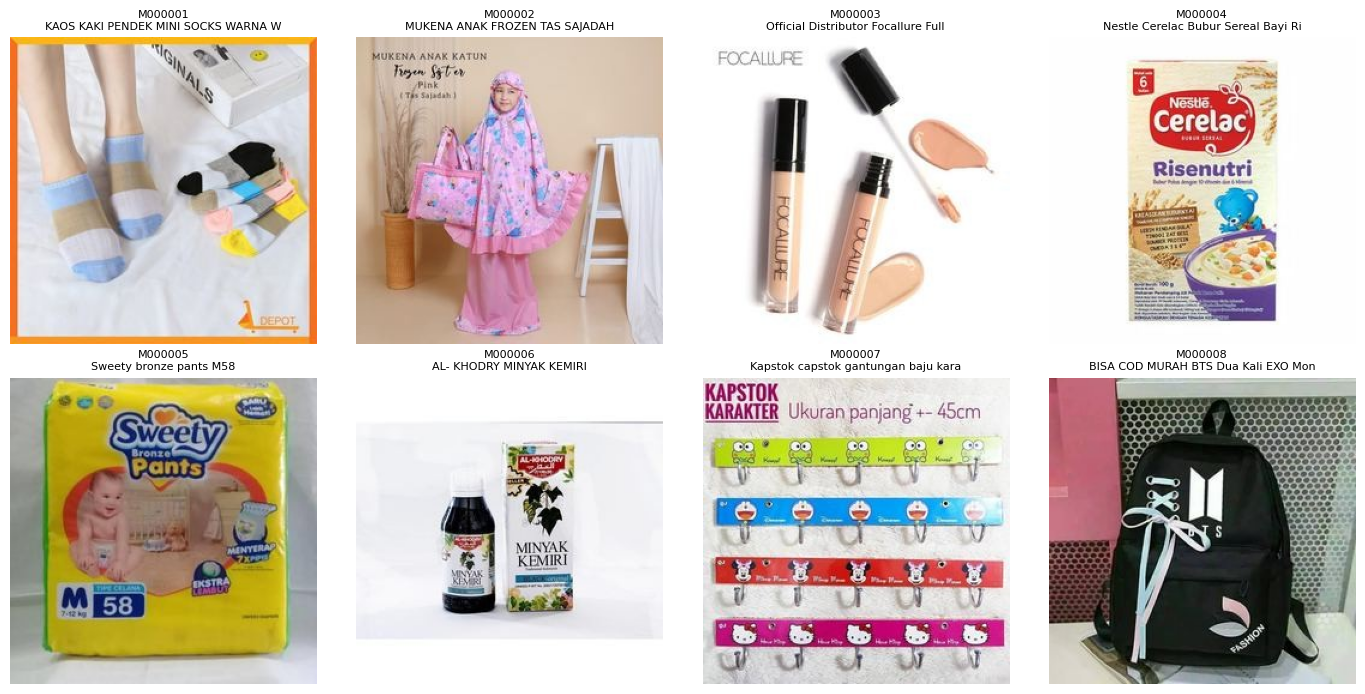

In [12]:
sample = products[products.image_path.fillna("").astype(bool)].head(8)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, row in zip(axes.ravel(), sample.itertuples()):
    try:
        ax.imshow(Image.open(row.image_path))
        ax.set_title(str(row.product_ref) + "\n" + str(row.title)[:35], fontsize=8)
    except Exception:
        pass
    ax.axis("off")
plt.tight_layout()
plt.show()

In [14]:
ref_to_idx = {ref: i for i, ref in enumerate(products.product_ref)}
ref_to_price = dict(zip(products.product_ref, products.price))
ref_to_title = dict(zip(products.product_ref, products.title))

def safe_float(x):
    try:
        return float(x)
    except Exception:
        return np.nan

def pair_similarity(ref_a, ref_b):
    a, b = str(ref_a).strip().upper(), str(ref_b).strip().upper()
    if a not in ref_to_idx or b not in ref_to_idx:
        return {"word_sim": 0.0, "char_sim": 0.0, "image_sim": np.nan,
                "price_sim": 0.0, "similarity_score": 0.0}
    ia, ib = ref_to_idx[a], ref_to_idx[b]
    word_sim = float(X_word[ia].multiply(X_word[ib]).sum())
    char_sim = float(X_char[ia].multiply(X_char[ib]).sum())

    image_sim = np.nan
    if a in image_features and b in image_features:
        va, vb = image_features[a], image_features[b]
        denom = np.linalg.norm(va) * np.linalg.norm(vb)
        image_sim = float(np.dot(va, vb) / denom) if denom else 0.0
        image_sim = max(0.0, min(1.0, image_sim))

    pa, pb = safe_float(ref_to_price.get(a)), safe_float(ref_to_price.get(b))
    price_sim = 0.0
    if np.isfinite(pa) and np.isfinite(pb):
        price_sim = float(np.exp(-abs(np.log1p(max(pa, 0)) - np.log1p(max(pb, 0)))))

    components = [(word_sim, 0.35), (char_sim, 0.40), (price_sim, 0.05)]
    if np.isfinite(image_sim):
        components.append((image_sim, 0.20))
    weight_sum = sum(w for _, w in components)
    score = sum(v*w for v, w in components) / weight_sum if weight_sum else 0.0
    return {"word_sim": word_sim, "char_sim": char_sim, "image_sim": image_sim,
            "price_sim": price_sim, "similarity_score": float(score)}

In [15]:
score_rows = []
for row in tqdm(pairs.itertuples(index=False, name=None), total=len(pairs), desc="Scoring pairs"):
    row_dict = dict(zip(pairs.columns, row))
    result = pair_similarity(row_dict[PAIR_COLS[0]], row_dict[PAIR_COLS[1]])
    score_rows.append(result)

score_df = pd.DataFrame(score_rows)
scored_pairs = pd.concat([pairs.reset_index(drop=True), score_df], axis=1)
known_a = pairs[PAIR_COLS[0]].astype(str).str.upper().isin(ref_to_idx)
known_b = pairs[PAIR_COLS[1]].astype(str).str.upper().isin(ref_to_idx)
print("Pairs:", len(pairs))
print("Pairs where both references were scraped:", int((known_a & known_b).sum()))
print("Pairs with at least one missing reference:", int((~(known_a & known_b)).sum()))
display(scored_pairs.head(10))

Scoring pairs:   0%|          | 0/6000 [00:00<?, ?it/s]

Pairs: 6000
Pairs where both references were scraped: 6000
Pairs with at least one missing reference: 0


,pair_ref,item_a,item_b,word_sim,char_sim,image_sim,price_sim,similarity_score
0,Q000001,M001717,M002153,0.000000,0.005035,0.336895,0.042857,0.071536
1,Q000002,M002364,M003380,0.097495,0.246146,0.203703,0.130000,0.179822
2,Q000003,M000218,M001820,0.000000,0.012647,0.038302,0.216667,0.023553
3,Q000004,M001448,M001956,0.512247,0.614136,0.979133,0.333333,0.637434
4,Q000005,M000041,M001166,0.354377,0.457963,0.044321,0.200000,0.326081
5,Q000006,M000571,M001097,0.561027,0.629575,0.595799,0.125000,0.573600
6,Q000007,M000386,M000555,0.703621,0.774079,0.981136,0.384615,0.771357
7,Q000008,M001415,M002779,0.371385,0.545901,0.743492,0.520000,0.523043
8,Q000009,M000667,M002619,0.000000,0.013399,0.027290,0.400000,0.030818
9,Q000010,M001843,M002944,0.000000,0.022426,0.702483,1.000000,0.199467


In [16]:
N_CLUSTERS = min(80, max(2, len(products) // 20)) if len(products) >= 40 else max(2, min(5, len(products)))
if len(products) >= 2:
    cluster_model = MiniBatchKMeans(n_clusters=N_CLUSTERS, random_state=42, batch_size=256, n_init=3)
    products["text_cluster"] = cluster_model.fit_predict(X_word)
    print("Cluster count:", products["text_cluster"].nunique())
    display(products[["product_ref", "title", "text_cluster"]].head(15))

Cluster count: 79


,product_ref,title,text_cluster
0,M000001,KAOS KAKI PENDEK MINI SOCKS WARNA WARNI,37
1,M000002,MUKENA ANAK FROZEN TAS SAJADAH,61
2,M000003,Official Distributor Focallure Full Coverage L...,37
3,M000004,Nestle Cerelac Bubur Sereal Bayi Risenutri,37
4,M000005,Sweety bronze pants M58,37
5,M000006,AL- KHODRY MINYAK KEMIRI,37
6,M000007,Kapstok capstok gantungan baju karakter {1 kg ...,37
7,M000008,BISA COD MURAH BTS Dua Kali EXO Monsta X Mau S...,20
8,M000009,PROMO( 1 KG 10 PCS ) Segi 3 segitiga soft pad ...,37
9,M000010,Shampo pentene,37


In [17]:
display(scored_pairs.sort_values("similarity_score", ascending=False).head(30))

,pair_ref,item_a,item_b,word_sim,char_sim,image_sim,price_sim,similarity_score
522,Q000523,M000100,M002681,1.0,1.0,0.979412,0.800000,0.985882
3165,Q003166,M001447,M001673,1.0,1.0,0.999783,0.615385,0.980726
3319,Q003320,M001881,M002850,1.0,1.0,0.992841,0.640000,0.980568
669,Q000670,M000028,M002843,1.0,1.0,0.949024,0.800000,0.979805
5862,Q005863,M000172,M001861,1.0,1.0,0.989287,0.615385,0.978627
3512,Q003513,M001026,M001811,1.0,1.0,0.965614,0.625000,0.974373
1908,Q001909,M000754,M002028,1.0,1.0,0.999902,0.400000,0.969980
4444,Q004445,M000240,M000338,1.0,1.0,0.999895,0.400000,0.969979
1375,Q001376,M000697,M003145,1.0,1.0,0.983613,0.461538,0.969799
1346,Q001347,M000682,M003025,1.0,1.0,0.995623,0.357143,0.966982


In [19]:
PREDICTION_COLUMN = "similarity_score"
submission = pairs.copy()
submission[PREDICTION_COLUMN] = score_df["similarity_score"].values
submission.to_csv("submission.csv", index=False)
products.to_csv("products.csv", index=False)
print("Saved submission.csv:", submission.shape)
display(submission.head())

Saved submission.csv: (6000, 4)


,pair_ref,item_a,item_b,similarity_score
0,Q000001,M001717,M002153,0.071536
1,Q000002,M002364,M003380,0.179822
2,Q000003,M000218,M001820,0.023553
3,Q000004,M001448,M001956,0.637434
4,Q000005,M000041,M001166,0.326081


In [20]:
try:
    from google.colab import files
    files.download("submission.csv")
    files.download("products.csv")
except Exception:
    print("Not running in Google Colab. Files are available in the current working directory.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
submission = pd.DataFrame({
    "pair_ref": pairs["pair_ref"],
    "match_score": score_df["similarity_score"]
})

submission.to_csv("submission1.csv", index=False)

print(submission.head())
print("Shape:", submission.shape)
print("Columns:", submission.columns.tolist())


  pair_ref  match_score
0  Q000001     0.071536
1  Q000002     0.179822
2  Q000003     0.023553
3  Q000004     0.637434
4  Q000005     0.326081
Shape: (6000, 2)
Columns: ['pair_ref', 'match_score']
